In [20]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import torchvision.models as models
from matplotlib import pyplot as plt

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

### Load Data


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
import os

# Search through Google Drive to find the correct path
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for d in dirs:
        if 'car-damage' in d.lower() or 'dataset' in d.lower():
            print(os.path.join(root, d))

/content/drive/MyDrive/Colab Notebooks/dataset


In [24]:
import shutil
import os

# Remove the existing local folder if you want a clean copy
if os.path.exists('/content/dataset'):
    shutil.rmtree('/content/dataset')

# Copy dataset from Google Drive to Colab's local storage
shutil.copytree('/content/drive/MyDrive/Colab Notebooks/dataset', '/content/dataset')

print("Dataset copied locally successfully!")

Dataset copied locally successfully!


In [25]:
dataset_path = "./dataset"

dataset = datasets.ImageFolder(dataset_path)
len(dataset)

2300

In [51]:
class_names = dataset.classes
class_names

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [27]:
num_classes = len(dataset.classes)
num_classes

6

In [28]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# 1. Define transform first
image_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Load dataset using that transform
dataset = datasets.ImageFolder(root='/content/dataset', transform=image_transform)

# 3. Split the dataset
train_size = int(0.75 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# 4. Create your data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print("Setup completed successfully!")

Setup completed successfully!


In [29]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [30]:
images[0].shape

torch.Size([3, 224, 224])

In [31]:
images[0].permute(1,2,0).shape

torch.Size([224, 224, 3])

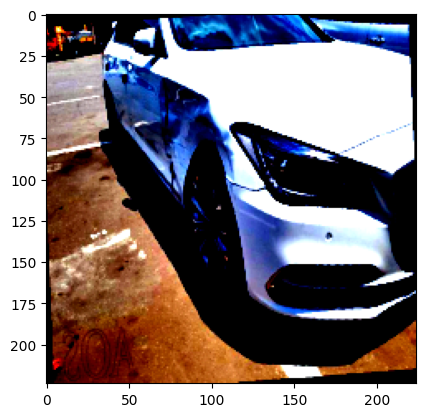

In [32]:
plt.imshow(images[0].permute(1,2,0))
plt.show()

**Model 1: CNN**

In [33]:
class CarClassifierCNN(nn.Module):
  def __init__(self, num_classes):
    super().__init__()
    self.network = nn. Sequential(
        nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=3, padding=1), #(16, 224, 224)
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #(16, 112, 112)
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (32, 56, 56)
        nn.Conv2d(in_channels=16, out_channels=64, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (64, 28, 28)
        nn.Flatten(),
        nn.Linear(64*9*9, 512),
        nn.ReLU(),
        nn.Linear(512, num_classes)


    )

  def forward(self, x):
    x = self.network(x)
    return x

In [34]:
model = CarClassifierCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [35]:


def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for batch_num, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            if (batch_num + 1) % 10 == 0:
                print(f"Batch: {batch_num + 1}, Epoch: {epoch + 1}, Loss: {loss.item():0.2f}")

            running_loss = loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)
        print(f"Epoch [{epoch + 1}/{epochs}], Avg loss: {epoch_loss:.4f}")

        # Evaluation phase
        model.eval()
        correct = 0
        total = 0
        all_labels = []
        all_predictions = []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        val_accuracy = 100 * correct / total
        print(f"Validation Accuracy: {val_accuracy:.2f}%")

    end = time.time()
    print(f"Execution time: {end - start} seconds")

    return all_labels, all_predictions



In [36]:
all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=5)

Batch: 10, Epoch: 1, Loss: 1.74
Batch: 20, Epoch: 1, Loss: 1.70
Batch: 30, Epoch: 1, Loss: 1.58
Batch: 40, Epoch: 1, Loss: 1.46
Batch: 50, Epoch: 1, Loss: 1.20
Epoch [1/5], Avg loss: 0.0230
Validation Accuracy: 42.61%
Batch: 10, Epoch: 2, Loss: 1.06
Batch: 20, Epoch: 2, Loss: 1.12
Batch: 30, Epoch: 2, Loss: 1.29
Batch: 40, Epoch: 2, Loss: 1.25
Batch: 50, Epoch: 2, Loss: 0.99
Epoch [2/5], Avg loss: 0.0186
Validation Accuracy: 54.96%
Batch: 10, Epoch: 3, Loss: 0.92
Batch: 20, Epoch: 3, Loss: 1.01
Batch: 30, Epoch: 3, Loss: 1.08
Batch: 40, Epoch: 3, Loss: 0.93
Batch: 50, Epoch: 3, Loss: 1.15
Epoch [3/5], Avg loss: 0.0168
Validation Accuracy: 56.17%
Batch: 10, Epoch: 4, Loss: 0.74
Batch: 20, Epoch: 4, Loss: 0.95
Batch: 30, Epoch: 4, Loss: 0.88
Batch: 40, Epoch: 4, Loss: 0.81
Batch: 50, Epoch: 4, Loss: 0.92
Epoch [4/5], Avg loss: 0.0153
Validation Accuracy: 55.65%
Batch: 10, Epoch: 5, Loss: 0.71
Batch: 20, Epoch: 5, Loss: 0.90
Batch: 30, Epoch: 5, Loss: 0.73
Batch: 40, Epoch: 5, Loss: 1.03


**Model 2: CNN with REGULARIZATION**

In [37]:
class CarClassifierCNNWithRegulaization(nn.Module):
  def __init__(self, num_classes):
    super().__init__()
    self.network = nn. Sequential(
        nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=3, padding=1), #(16, 224, 224)
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0), #(16, 112, 112)
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (32, 56, 56)
        nn.Conv2d(in_channels=16, out_channels=64, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (64, 28, 28)
        nn.Flatten(),
        nn.Linear(64*9*9, 512),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(512, num_classes)


    )

  def forward(self, x):
    x = self.network(x)
    return x

In [38]:
model = CarClassifierCNNWithRegulaization(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.97
Batch: 20, Epoch: 1, Loss: 1.65
Batch: 30, Epoch: 1, Loss: 1.40
Batch: 40, Epoch: 1, Loss: 1.65
Batch: 50, Epoch: 1, Loss: 1.42
Epoch [1/10], Avg loss: 0.0197
Validation Accuracy: 51.48%
Batch: 10, Epoch: 2, Loss: 1.17
Batch: 20, Epoch: 2, Loss: 1.11
Batch: 30, Epoch: 2, Loss: 1.27
Batch: 40, Epoch: 2, Loss: 1.26
Batch: 50, Epoch: 2, Loss: 1.25
Epoch [2/10], Avg loss: 0.0214
Validation Accuracy: 54.61%
Batch: 10, Epoch: 3, Loss: 1.23
Batch: 20, Epoch: 3, Loss: 1.14
Batch: 30, Epoch: 3, Loss: 1.29
Batch: 40, Epoch: 3, Loss: 1.03
Batch: 50, Epoch: 3, Loss: 1.06
Epoch [3/10], Avg loss: 0.0218
Validation Accuracy: 55.13%
Batch: 10, Epoch: 4, Loss: 1.06
Batch: 20, Epoch: 4, Loss: 1.05
Batch: 30, Epoch: 4, Loss: 0.75
Batch: 40, Epoch: 4, Loss: 0.99
Batch: 50, Epoch: 4, Loss: 1.24
Epoch [4/10], Avg loss: 0.0161
Validation Accuracy: 57.39%
Batch: 10, Epoch: 5, Loss: 1.05
Batch: 20, Epoch: 5, Loss: 0.96
Batch: 30, Epoch: 5, Loss: 1.06
Batch: 40, Epoch: 5, Loss: 0

**Model 3: Transfer Learning with EfficientNet**

In [39]:
class CarClassifierEfficientNet(nn.Module):
  def __init__(self, num_classes):
    super().__init__()
    self.model = models.efficientnet_b0(weights='DEFAULT')

    for param in self.model.parameters():
      param.requires_grad = False

    in_features = self.model.classifier[1].in_features

    self.model.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(in_features, num_classes)
    )

  def forward(self, x):
    x = self.model(x)
    return x

In [40]:
model = CarClassifierEfficientNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

all_labels, all_predictions = train_model(model, criterion, optimizer, epochs=10)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 255MB/s]


Batch: 10, Epoch: 1, Loss: 1.64
Batch: 20, Epoch: 1, Loss: 1.24
Batch: 30, Epoch: 1, Loss: 1.38
Batch: 40, Epoch: 1, Loss: 1.30
Batch: 50, Epoch: 1, Loss: 1.44
Epoch [1/10], Avg loss: 0.0237
Validation Accuracy: 59.65%
Batch: 10, Epoch: 2, Loss: 1.18
Batch: 20, Epoch: 2, Loss: 1.29
Batch: 30, Epoch: 2, Loss: 1.14
Batch: 40, Epoch: 2, Loss: 1.06
Batch: 50, Epoch: 2, Loss: 1.15
Epoch [2/10], Avg loss: 0.0193
Validation Accuracy: 58.96%
Batch: 10, Epoch: 3, Loss: 1.19
Batch: 20, Epoch: 3, Loss: 1.01
Batch: 30, Epoch: 3, Loss: 1.00
Batch: 40, Epoch: 3, Loss: 1.03
Batch: 50, Epoch: 3, Loss: 1.03
Epoch [3/10], Avg loss: 0.0147
Validation Accuracy: 62.61%
Batch: 10, Epoch: 4, Loss: 1.08
Batch: 20, Epoch: 4, Loss: 0.99
Batch: 30, Epoch: 4, Loss: 0.97
Batch: 40, Epoch: 4, Loss: 0.77
Batch: 50, Epoch: 4, Loss: 0.79
Epoch [4/10], Avg loss: 0.0189
Validation Accuracy: 66.61%
Batch: 10, Epoch: 5, Loss: 0.99
Batch: 20, Epoch: 5, Loss: 0.90
Batch: 30, Epoch: 5, Loss: 1.00
Batch: 40, Epoch: 5, Loss: 1

**Model 3: Transfer Learning with ResNet**

In [41]:
class CarClassifierResNet(nn.Module):
  def __init__(self, num_classes):
    super().__init__()
    self.model = models.resnet50(weights='DEFAULT')

    for param in self.model.parameters():
      param.requires_grad = False


    for param in self.model.layer4.parameters():
      param.requires_grad = True


    self.model.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(self.model.fc.in_features, num_classes)
    )

  def forward(self, x):
    x = self.model(x)
    return x

In [42]:
model = CarClassifierResNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 148MB/s]


Batch: 10, Epoch: 1, Loss: 1.02
Batch: 20, Epoch: 1, Loss: 0.67
Batch: 30, Epoch: 1, Loss: 1.14
Batch: 40, Epoch: 1, Loss: 0.67
Batch: 50, Epoch: 1, Loss: 0.48
Epoch [1/10], Avg loss: 0.0158
Validation Accuracy: 76.52%
Batch: 10, Epoch: 2, Loss: 0.79
Batch: 20, Epoch: 2, Loss: 0.46
Batch: 30, Epoch: 2, Loss: 0.41
Batch: 40, Epoch: 2, Loss: 0.48
Batch: 50, Epoch: 2, Loss: 0.65
Epoch [2/10], Avg loss: 0.0117
Validation Accuracy: 75.13%
Batch: 10, Epoch: 3, Loss: 0.35
Batch: 20, Epoch: 3, Loss: 0.19
Batch: 30, Epoch: 3, Loss: 0.18
Batch: 40, Epoch: 3, Loss: 0.26
Batch: 50, Epoch: 3, Loss: 0.49
Epoch [3/10], Avg loss: 0.0076
Validation Accuracy: 80.17%
Batch: 10, Epoch: 4, Loss: 0.32
Batch: 20, Epoch: 4, Loss: 0.16
Batch: 30, Epoch: 4, Loss: 0.11
Batch: 40, Epoch: 4, Loss: 0.23
Batch: 50, Epoch: 4, Loss: 0.18
Epoch [4/10], Avg loss: 0.0059
Validation Accuracy: 80.35%
Batch: 10, Epoch: 5, Loss: 0.36
Batch: 20, Epoch: 5, Loss: 0.24
Batch: 30, Epoch: 5, Loss: 0.07
Batch: 40, Epoch: 5, Loss: 0

## **I ran hyperprameter tunning with best parameters for resnet models are (1) Dropout rate= 0.2 (2) Learning Rate= 0.005**





Model 4: ResNet with best **hyperparameter**

In [48]:
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
        super().__init__()
        self.model = models.resnet50(weights='DEFAULT')

        for param in self.model.parameters():
            param.requires_grad = False

        for param in self.model.layer4.parameters():
            param.requires_grad = True

        self.model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(self.model.fc.in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)

In [49]:
model = CarClassifierResNet(num_classes=num_classes, dropout_rate=0.2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.005)

labels, predictions = train_model(model, criterion, optimizer, epochs=10)

Batch: 10, Epoch: 1, Loss: 1.34
Batch: 20, Epoch: 1, Loss: 0.91
Batch: 30, Epoch: 1, Loss: 0.67
Batch: 40, Epoch: 1, Loss: 0.69
Batch: 50, Epoch: 1, Loss: 0.65
Epoch [1/10], Avg loss: 0.0150
Validation Accuracy: 63.83%
Batch: 10, Epoch: 2, Loss: 0.55
Batch: 20, Epoch: 2, Loss: 0.38
Batch: 30, Epoch: 2, Loss: 0.41
Batch: 40, Epoch: 2, Loss: 0.74
Batch: 50, Epoch: 2, Loss: 0.66
Epoch [2/10], Avg loss: 0.0090
Validation Accuracy: 73.22%
Batch: 10, Epoch: 3, Loss: 0.35
Batch: 20, Epoch: 3, Loss: 0.39
Batch: 30, Epoch: 3, Loss: 0.28
Batch: 40, Epoch: 3, Loss: 0.32
Batch: 50, Epoch: 3, Loss: 0.30
Epoch [3/10], Avg loss: 0.0073
Validation Accuracy: 78.78%
Batch: 10, Epoch: 4, Loss: 0.46
Batch: 20, Epoch: 4, Loss: 0.12
Batch: 30, Epoch: 4, Loss: 0.28
Batch: 40, Epoch: 4, Loss: 0.47
Batch: 50, Epoch: 4, Loss: 0.35
Epoch [4/10], Avg loss: 0.0054
Validation Accuracy: 80.52%
Batch: 10, Epoch: 5, Loss: 0.15
Batch: 20, Epoch: 5, Loss: 0.16
Batch: 30, Epoch: 5, Loss: 0.14
Batch: 40, Epoch: 5, Loss: 0

In [50]:
from sklearn.metrics import classification_report

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.75      0.84      0.80       120
           1       0.72      0.80      0.76       101
           2       0.94      0.84      0.89       116
           3       0.83      0.64      0.72        85
           4       0.64      0.84      0.73        73
           5       0.89      0.74      0.81        80

    accuracy                           0.79       575
   macro avg       0.80      0.78      0.78       575
weighted avg       0.80      0.79      0.79       575



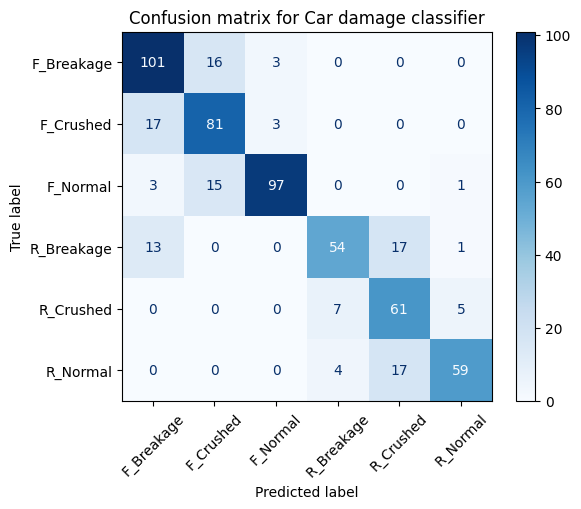

In [53]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))

# FIXED: Changed plt.cm.blues to plt.cm.Blues (or use 'Blues')
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)

plt.title("Confusion matrix for Car damage classifier")
plt.show()

In [54]:
torch.save(model.state_dict(), 'saved_model.pth')